# Analiza cantitativă a piețelor de energie — Cursul 6: Surse regenerabile și stocare
Prof. dr. Daniel Traian Pele — Academia de Studii Economice din București; Academia Română, Institutul de Prognoză Economică

Acest notebook Jupyter reproduce cifrele și graficele din cursul 6 pe datele reale din `../data/clean` (vezi `../data/SOURCES.md`; rulați o dată `python3 data/download_L6.py` pentru fișierele de producție pe 15 minute). Numerele secțiunilor (§) corespund indicațiilor *Exercițiu practic* de pe diapozitive.

**Convenții.** Zile de livrare după ora Europei Centrale (CET); perioada se încheie cu ultima lună completă; energia = puterea medie (MW) × durata intervalului; un interval de 15 minute contează 0,25 h; valorile lipsă rămîn lipsă.

## §1 Datele și creșterea producției solare

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, statsmodels.api as sm, json, warnings
from scipy import sparse
from scipy.optimize import linprog
warnings.filterwarnings('ignore')
DATA = '../data/clean/'
TZ = 'Europe/Brussels'
ETA, CYCLES, DURS = 0.85, 1.0, (1, 2, 4)
R_DISC, LIFE = 0.08, 15

PX = pd.read_csv(DATA + 'power_da_prices_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
PX.index = PX.index.tz_convert(TZ)
PX['dur'] = PX['mtu_minutes'] / 60.0
GN = {}
for c in ('ro', 'bg', 'hu'):
    g = pd.read_csv(DATA + f'generation_{c}_mw_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
    g.index = g.index.tz_convert(TZ); GN[c.upper()] = g
raw_last = min(PX['RO'].dropna().index.max().tz_localize(None), GN['RO']['solar'].dropna().index.max().tz_localize(None))
END = pd.Timestamp(((raw_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
END_X = (END + pd.Timedelta(days=1)).tz_localize(TZ)
PX = PX[PX.index < END_X]
Y = END.year
MTU15 = pd.Timestamp('2025-10-01').tz_localize(TZ)
LTM0 = (END + pd.Timedelta(days=1) - pd.DateOffset(years=1)).tz_localize(TZ)
print('cut-off:', END.date(), '| last 12 months from', LTM0.date())

def hfloor(idx):
    """Start of the clock hour, computed in UTC (no ambiguity on the autumn DST day)."""
    return idx.tz_convert("UTC").floor("1h").tz_convert(TZ)


def on_price_grid(zone, gen):
    """Generation columns on the price grid of `zone`: hourly mean for hourly prices; 15-min value for 15-min prices
    (hourly value repeated when the source is hourly, as for Bulgaria). Returns a DataFrame aligned to PX.index."""
    g = GN[gen].drop(columns=["mtu_minutes"]).copy()
    hourly = g.resample("1h").mean()
    out = hourly.reindex(hfloor(PX.index)).set_axis(PX.index)
    q15 = PX["mtu_minutes"] == 15
    if (GN[gen]["mtu_minutes"] == 15).loc[GN[gen].index >= MTU15].all():
        g15 = g.resample("15min").mean()
        out.loc[q15] = g15.reindex(PX.index[q15]).values
    return out


def wmean(p, w):
    m = p.notna() & w.notna()
    return float((p[m] * w[m]).sum() / w[m].sum()) if w[m].sum() > 0 else np.nan


GR = {z: on_price_grid(z, z) for z in ('RO', 'BG', 'HU')}
ro = GR['RO']
LOC_YEAR = PX.index.year
CAP = pd.read_csv(DATA + 'installed_capacity_yearly.csv')
print(CAP[CAP['type'].str.startswith('Solar')].pivot(index='year', columns='country', values='gw').loc[2019:])
twh = {y: (ro['solar'][LOC_YEAR == y] * PX['dur'][LOC_YEAR == y]).sum() / 1e6 for y in range(2019, Y + 1)}
print({y: round(v, 2) for y, v in twh.items()}, '(TWh of Romanian solar; last year to the cut-off)')

cut-off: 2026-10-31 | last 12 months from 2025-11-01
country    BG    HU    RO
year                     
2019     1.08  1.41  1.16
2020     1.25  1.83  1.14
2021     1.73  2.52  1.16
2022     3.09  3.30  1.18
2023     4.57  4.03  1.29
2024     6.10  8.28  1.59
2025     7.16  8.97  2.79
{2019: np.float64(1.37), 2020: np.float64(1.34), 2021: np.float64(1.29), 2022: np.float64(1.37), 2023: np.float64(1.46), 2024: np.float64(2.09), 2025: np.float64(2.72), 2026: np.float64(4.32)} (TWh of Romanian solar; last year to the cut-off)


## §2 Efectul ordinii de merit pe curbele reale OPCOM
Adăugăm X MW de ofertă la 0 EUR/MWh (solar, eolian) sau X MW de cerere la orice preț (încărcarea bateriilor) și recalculăm prețul de închidere. Fluxurile transfrontaliere, blocurile și ordinele orare rămîn la valorile acceptate, deci rezultatul este o limită superioară pentru piața cuplată.

Q45 official 152.23 | +25 MW supply -> 131.4 | +100 MW demand -> 234.65
Q77 official 244.0 | +25 MW supply -> 187.53 | +100 MW demand -> 281.6


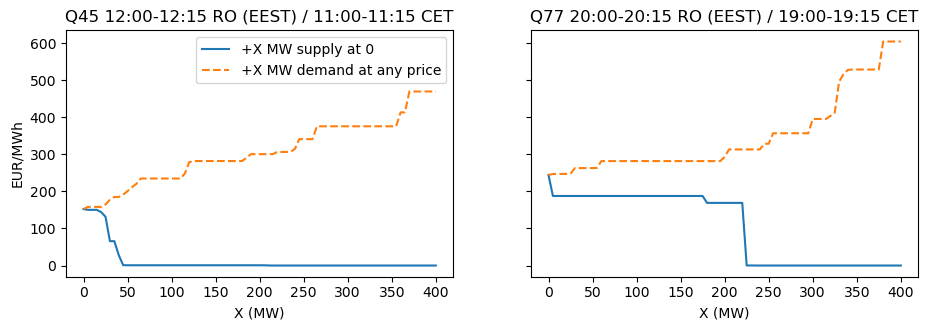

50 MW of batteries: evening - midday spread = -13.15 EUR/MWh
100 MW of batteries: evening - midday spread = -47.12 EUR/MWh
200 MW of batteries: evening - midday spread = -131.4 EUR/MWh


In [2]:
CURVES = pd.read_csv(DATA + 'opcom_pzu_curves.csv')
CMETA = json.load(open(DATA + 'opcom_pzu_curves_meta.json'))

def curve_fns(lab):
    """Cumulative supply S(p) (MW offered at prices <= p) and demand D(p) (MW bid at prices >= p), piecewise linear in
    the published points; ties in price are separated by 1e-7 EUR/MWh so the functions are single-valued."""
    s = CURVES[(CURVES["interval"] == lab) & (CURVES["side"] == "supply")]
    dm = CURVES[(CURVES["interval"] == lab) & (CURVES["side"] == "demand")]
    ps = s["price_eur_mwh"].values + np.arange(len(s)) * 1e-7
    pdm = dm["price_eur_mwh"].values[::-1] + np.arange(len(dm)) * 1e-7
    qs, qd = s["quantity_mw"].values, dm["quantity_mw"].values[::-1]
    return (lambda p: np.interp(p, ps, qs)), (lambda p: np.interp(p, pdm, qd))


def clear(S, D, xs=0.0, xd=0.0, p_s=0.0):
    """Clearing price after adding xs MW of supply offered at p_s and xd MW of demand bid at any price: lowest p with
    S(p) + xs*1[p >= p_s] >= D(p) + xd (bisection on the monotone excess supply)."""
    lo, hi = -600.0, 4000.0
    for _ in range(70):
        m_ = 0.5 * (lo + hi)
        if S(m_) + xs * (m_ >= p_s) - D(m_) - xd >= 0:
            hi = m_
        else:
            lo = m_
    return hi


XGRID = np.arange(0, 401, 5)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
res = {}
for ax, iv in zip(axs, CMETA['intervals']):
    S, D_ = curve_fns(iv['interval_label']); P0 = iv['official_clearing_price_eur_mwh']
    sup = [clear(S, D_, xs=x) if x else P0 for x in XGRID]; dem = [clear(S, D_, xd=x) if x else P0 for x in XGRID]
    res[iv['opcom_interval']] = (sup, dem)
    ax.plot(XGRID, sup, label='+X MW supply at 0'); ax.plot(XGRID, dem, '--', label='+X MW demand at any price')
    ax.set_title(iv['interval_label']); ax.set_xlabel('X (MW)')
    print(iv['interval_label'][:3], 'official', P0, '| +25 MW supply ->', round(sup[5], 2), '| +100 MW demand ->', round(dem[20], 2))
axs[0].set_ylabel('EUR/MWh'); axs[0].legend(); plt.show()
# batteries: X MW charging at midday (Q45) and discharging in the evening (Q77)
for x in (50, 100, 200):
    k = int(x / 5)
    print(f'{x} MW of batteries: evening - midday spread =', round(res[77][0][k] - res[45][1][k], 2), 'EUR/MWh')

## §3 Prețul, solarul, eolianul și consumul rezidual: regresie pe date orare
Efecte fixe pentru lună, oră și ziua săptămînii; erori standard HAC (48 de decalaje).

load     40.74
wind    -15.26
solar   -26.73
dtype: float64 load     1.59
wind     1.04
solar    2.17
dtype: float64 R2 0.647


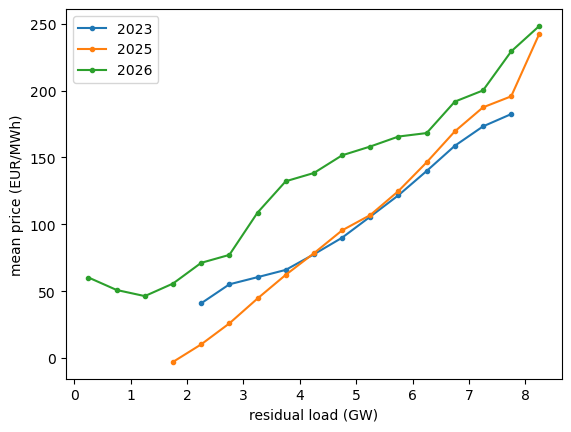

In [3]:
H = pd.DataFrame({'P': PX['RO'], 'dur': PX['dur'], 'load': ro['load'], 'wind': ro['wind_onshore'], 'solar': ro['solar']})
H = H[H.index >= pd.Timestamp('2023-01-01').tz_localize(TZ)]
HH = (H[['P', 'load', 'wind', 'solar']].mul(H['dur'], axis=0).groupby(hfloor(H.index)).sum()
      .div(H['dur'].groupby(hfloor(H.index)).sum(), axis=0)).dropna()
HH[['load', 'wind', 'solar']] /= 1000
HH['resid'] = HH['load'] - HH['wind'] - HH['solar']
fe = pd.get_dummies(pd.DataFrame({'m': HH.index.strftime('%Y-%m'), 'h': HH.index.hour.astype(str), 'w': HH.index.dayofweek.astype(str)}), drop_first=True).astype(float)
fe.index = HH.index
R1 = sm.OLS(HH['P'], sm.add_constant(pd.concat([HH[['load', 'wind', 'solar']], fe], axis=1))).fit(cov_type='HAC', cov_kwds={'maxlags': 48})
print(R1.params[['load', 'wind', 'solar']].round(2), R1.bse[['load', 'wind', 'solar']].round(2), 'R2', round(R1.rsquared, 3))
for y in (2023, Y - 1, Y):
    s = HH[HH.index.year == y]; b = s.groupby(pd.cut(s['resid'], np.arange(-2, 9.01, 0.5)), observed=True)['P'].agg(['mean', 'count'])
    b = b[b['count'] >= 20]; plt.plot([i.mid for i in b.index], b['mean'], 'o-', ms=3, label=str(y))
plt.xlabel('residual load (GW)'); plt.ylabel('mean price (EUR/MWh)'); plt.legend(); plt.show()

## §4 Prețul capturat, rata de captare și canibalizarea

tech  solar  wind_onshore
year                     
2019  104.5          93.6
2020   92.2          92.6
2021   90.3          99.6
2022   99.5          88.4
2023   80.2          97.4
2024   65.7          90.2
2025   59.4          98.7
2026   61.9         103.0
zone     BG     HU     RO
year                     
2019  103.8    NaN  104.5
2020   94.2   89.2   92.2
2021   92.8   90.5   90.3
2022   95.4  102.1   99.5
2023   79.6   80.7   80.2
2024   70.8   63.4   65.7
2025   68.6   57.5   59.4
2026   77.1   57.3   61.9


slope b = -4.2 SE 1.03
2019 solar energy in cheapest 10% of hours: 7.6%
2023 solar energy in cheapest 10% of hours: 18.2%
2025 solar energy in cheapest 10% of hours: 32.1%
2026 solar energy in cheapest 10% of hours: 23.4%


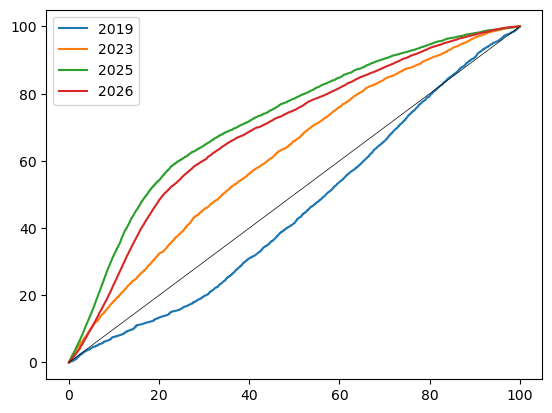

In [4]:
def capture(zone, tech, mask):
    p, w = PX[zone], GR[zone if zone != "DE_LU" else "RO"][tech] * PX["dur"]
    m = mask & p.notna() & w.notna()
    base_m = mask & p.notna()
    cp = float((p[m] * w[m]).sum() / w[m].sum())
    base = float((p[base_m] * PX["dur"][base_m]).sum() / PX["dur"][base_m].sum())
    return cp, base, float(w[m].sum())


rows = []
for z in ('RO', 'BG', 'HU'):
    for tech in ('solar', 'wind_onshore'):
        for y in range(2019, Y + 1):
            m = pd.Series(LOC_YEAR == y, index=PX.index)
            if GR[z][tech][m].notna().sum() < 0.9 * m.sum():
                continue
            cp, base, e = capture(z, tech, m); rows.append((z, tech, y, round(cp, 1), round(base, 1), round(cp / base * 100, 1)))
CT = pd.DataFrame(rows, columns=['zone', 'tech', 'year', 'CP', 'base', 'CR %'])
print(CT[CT.zone == 'RO'].pivot(index='year', columns='tech', values='CR %'))
print(CT[CT.tech == 'solar'].pivot(index='year', columns='zone', values='CR %'))

# monthly cannibalisation regression (Romania)
mon = []
for per in pd.period_range('2019-01', END.strftime('%Y-%m'), freq='M'):
    mk = pd.Series(PX.index.to_period('M') == per, index=PX.index)
    cp, base, e = capture('RO', 'solar', mk); ld = (ro['load'][mk] * PX['dur'][mk]).sum()
    mon.append((cp / base * 100, e / ld * 100))
mon = pd.DataFrame(mon, columns=['cr', 'share'])
rc = sm.OLS(mon['cr'], sm.add_constant(mon['share'])).fit(cov_type='HAC', cov_kwds={'maxlags': 6})
print('slope b =', round(rc.params['share'], 2), 'SE', round(rc.bse['share'], 2))

# share of solar energy sold in the cheapest 10% of hours
for y in (2019, 2023, 2025, Y):
    m = (LOC_YEAR == y) & PX['RO'].notna().values & ro['solar'].notna().values
    p_, g_, w_ = PX['RO'][m].values, ro['solar'][m].values, PX['dur'][m].values
    o = np.argsort(p_, kind='stable'); tsh = np.cumsum(w_[o]) / w_.sum(); esh = np.cumsum((g_ * w_)[o]) / (g_ * w_).sum()
    print(y, 'solar energy in cheapest 10%% of hours: %.1f%%' % (esh[np.searchsorted(tsh, 0.10)] * 100))
    plt.plot(tsh * 100, esh * 100, label=str(y))
plt.plot([0, 100], [0, 100], 'k', lw=0.5); plt.legend(); plt.show()

## §5 Prețurile negative: ore echivalente, valoarea opririi, sferturile de oră ascunse

In [5]:
neg = pd.DataFrame({z: {y: PX['dur'][(LOC_YEAR == y) & (PX[z] < 0).values].sum() for y in range(2019, Y + 1)} for z in ['RO', 'BG', 'HU', 'DE_LU']})
print(neg.round(2))
m = (LOC_YEAR == 2025) & PX['RO'].notna().values & ro['solar'].notna().values
p_, e_ = PX['RO'][m], ro['solar'][m] * PX['dur'][m]
print('2025: share of solar output at negative prices %.1f%%' % (e_[p_ < 0].sum() / e_.sum() * 100),
      '| gain from stopping, EUR per MWh of output: %.2f' % ((p_.clip(lower=0) * e_).sum() / e_.sum() - (p_ * e_).sum() / e_.sum()))
q = PX.loc[PX.index >= MTU15, ['RO']].copy(); q['hm'] = q['RO'].groupby(hfloor(q.index)).transform('mean')
print('negative quarter-hours:', int((q['RO'] < 0).sum()), '= %.2f h;' % ((q['RO'] < 0).sum() * 0.25),
      'inside hours with a non-negative average:', int(((q['RO'] < 0) & (q['hm'] >= 0)).sum()))

          RO      BG     HU   DE_LU
2019    0.00    0.00    0.0  211.00
2020    0.00    0.00    4.0  298.00
2021    0.00    0.00    8.0  139.00
2022    0.00    0.00    0.0   69.00
2023   32.00   11.00   74.0  301.00
2024   85.00   55.00  262.0  457.00
2025  196.00  170.00  281.0  574.75
2026  171.75  152.25  223.5  465.00
2025: share of solar output at negative prices 6.2% | gain from stopping, EUR per MWh of output: 0.63
negative quarter-hours: 687 = 171.75 h; inside hours with a non-negative average: 26


## §6 Profilul zilnic și diferențele zilnice de preț

winter min 88.6 at slot 95, max 186.5 at slot 67
spring min 23.0 at slot 51, max 208.3 at slot 79
summer min 44.9 at slot 55, max 270.5 at slot 79
autumn min 111.0 at slot 51, max 259.2 at slot 78


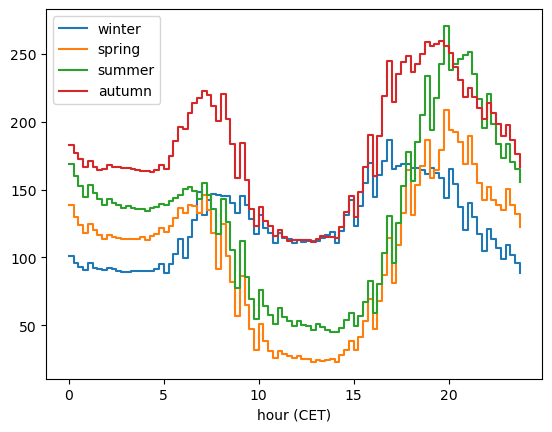

RO {2019: 44.8, 2020: 33.2, 2021: 90.3, 2022: 218.8, 2023: 117.1, 2024: 171.6, 2025: 151.1, 2026: 173.9}


BG {2019: 40.9, 2020: 30.2, 2021: 80.6, 2022: 221.8, 2023: 116.7, 2024: 167.6, 2025: 153.0, 2026: 149.8}


HU {2019: 39.5, 2020: 32.3, 2021: 82.8, 2022: 190.2, 2023: 103.9, 2024: 167.0, 2025: 149.6, 2026: 186.8}


DE_LU {2019: 28.3, 2020: 30.0, 2021: 75.6, 2022: 177.2, 2023: 91.7, 2024: 103.8, 2025: 116.1, 2026: 151.5}


In [6]:
def day_groups(zone, start=None, end=None, hourly=False):
    """Prices per CET delivery day (complete days only: 23/24/25 hours or 92/96/100 quarter-hours)."""
    s = PX[[zone, "dur"]]
    if start is not None:
        s = s[s.index >= start]
    if end is not None:
        s = s[s.index < end]
    if hourly:
        s = s.groupby(hfloor(s.index)).agg({zone: "mean", "dur": "sum"})
    out = {}
    for dd, g in s.groupby(s.index.tz_localize(None).normalize()):
        if g[zone].notna().all() and abs(g["dur"].sum() - round(g["dur"].sum())) < 1e-9 and round(g["dur"].sum()) in (23, 24, 25):
            out[dd] = (g[zone].values.astype(float), g["dur"].values.astype(float))
    return out


def tbk(p, dur, k):
    """Top-k minus bottom-k hours spread of one day (duration-weighted means of the k most expensive / cheapest hours)."""
    o = np.argsort(p)
    def avg(idx):
        w, acc, tot = dur[idx], 0.0, 0.0
        for i_, wi in zip(idx, w):
            take = min(wi, k - tot)
            if take <= 0:
                break
            acc += p[i_] * take
            tot += take
        return acc / tot
    return avg(o[::-1]) - avg(o)


qq = PX.loc[PX.index >= max(LTM0, MTU15), ['RO']].copy(); qq['slot'] = qq.index.hour * 4 + qq.index.minute // 15
for s, ms in {'winter': [12, 1, 2], 'spring': [3, 4, 5], 'summer': [6, 7, 8], 'autumn': [9, 10, 11]}.items():
    pr = qq[qq.index.month.isin(ms)].groupby('slot')['RO'].mean(); plt.step(np.arange(96) / 4, pr.values, where='post', label=s)
    print(s, 'min %.1f at slot %d, max %.1f at slot %d' % (pr.min(), pr.idxmin(), pr.max(), pr.idxmax()))
plt.legend(); plt.xlabel('hour (CET)'); plt.show()
for z in ['RO', 'BG', 'HU', 'DE_LU']:
    dg = day_groups(z, start=pd.Timestamp('2019-01-01').tz_localize(TZ), hourly=True)
    sp = pd.Series({d: tbk(p, w, 2) for d, (p, w) in dg.items()})
    print(z, sp.groupby(sp.index.year).mean().round(1).to_dict())

## §7 Programul liniar al bateriei: informație perfectă și reguli de prognoză
Cîte un program liniar pentru fiecare zi de livrare (HiGHS). Regulile folosesc numai prețurile cunoscute la 12:00 CET în ziua d−1. Durează aproximativ un minut.

In [7]:
def battery_day(p, dur, E, P=1.0, eta=ETA, cycles=CYCLES):
    """Optimal charge c_t and discharge d_t (MW) of a P-MW / E-MWh battery for one day of prices p_t (EUR/MWh) and
    interval lengths dur_t (h). max sum_t p_t (d_t - c_t) dur_t  s.t.  s_t = s_{t-1} + sqrt(eta) c_t dur_t - d_t dur_t / sqrt(eta),
    0 <= s_t <= E, s_0 = s_T = 0, 0 <= c_t, d_t <= P, sum_t d_t dur_t / sqrt(eta) <= cycles * E.  Returns (c, d)."""
    n = len(p)
    r = np.sqrt(eta)
    cost = np.concatenate([p * dur, -p * dur, np.zeros(n)])
    I = sparse.identity(n, format="csr")
    Lw = sparse.diags([np.ones(n), -np.ones(n - 1)], [0, -1], format="csr")         # s_t - s_{t-1}
    A_eq = sparse.hstack([-r * sparse.diags(dur), sparse.diags(dur / r), Lw], format="csr")
    A_eq = sparse.vstack([A_eq, sparse.hstack([sparse.csr_matrix((1, 2 * n)), sparse.csr_matrix(([1.0], ([0], [n - 1])), shape=(1, n))])])
    b_eq = np.zeros(n + 1)
    A_ub = sparse.hstack([sparse.csr_matrix((1, n)), sparse.csr_matrix(dur / r), sparse.csr_matrix((1, n))], format="csr")
    bounds = [(0, P)] * (2 * n) + [(0, E)] * n
    res = linprog(cost, A_ub=A_ub, b_ub=[cycles * E], A_eq=A_eq, b_eq=b_eq, bounds=bounds, method="highs")
    x = res.x
    del I
    return x[:n], x[n:2 * n]


def revenue(p, dur, c, dd_):
    return float(np.sum(p * (dd_ - c) * dur))


def run_battery(dg, E, forecast=None):
    """Daily revenue (EUR per MW) with perfect foresight, or with the schedule optimised on `forecast` (dict day -> prices)."""
    out = {}
    for day, (p, w) in dg.items():
        if forecast is None:
            c, dch = battery_day(p, w, E)
        else:
            f = forecast.get(day)
            if f is None or len(f) != len(p):
                continue
            c, dch = battery_day(f, w, E)
        out[day] = revenue(p, w, c, dch)
    return pd.Series(out)


def yesterday(dg):
    """Forecast for day d = the prices of day d-1 (known at gate closure on d-1)."""
    return {day: dg[day - pd.Timedelta(days=1)][0] for day in dg if (day - pd.Timedelta(days=1)) in dg}


def week_ago_mean(dg):
    """Forecast for day d = mean profile of days d-1 ... d-7 with the same number of intervals (known at gate closure)."""
    out = {}
    for day in dg:
        past = [dg[day - pd.Timedelta(days=j)][0] for j in range(1, 8) if (day - pd.Timedelta(days=j)) in dg and
                len(dg[day - pd.Timedelta(days=j)][0]) == len(dg[day][0])]
        if len(past) >= 5:
            out[day] = np.mean(past, axis=0)
    return out


dg_all = day_groups('RO', start=pd.Timestamp('2019-01-01').tz_localize(TZ))
pf2 = run_battery(dg_all, 2)
print('2-hour battery, perfect foresight, thousand EUR per MW and year:',
      (pf2.groupby(pf2.index.year).sum() / 1000).round(1).to_dict())
ltm = day_groups('RO', start=LTM0); ext = day_groups('RO', start=LTM0 - pd.Timedelta(days=8))
LT = {}
for E in DURS:
    pf = run_battery(ltm, E); wk = run_battery(ltm, E, week_ago_mean(ext)); yd = run_battery(ltm, E, yesterday(ext))
    cm = pf.index.intersection(wk.index).intersection(yd.index); LT[E] = pf
    print(f'{E} h: perfect {pf.sum()/1000:.1f} kEUR/MW; 7-day rule {wk[cm].sum()/pf[cm].sum()*100:.1f}%; yesterday {yd[cm].sum()/pf[cm].sum()*100:.1f}%')

2-hour battery, perfect foresight, thousand EUR per MW and year: {2019: 26.3, 2020: 19.4, 2021: 51.7, 2022: 125.0, 2023: 71.6, 2024: 110.2, 2025: 98.7, 2026: 100.5}


1 h: perfect 61.0 kEUR/MW; 7-day rule 82.0%; yesterday 75.0%


2 h: perfect 111.2 kEUR/MW; 7-day rule 84.9%; yesterday 79.1%


4 h: perfect 190.9 kEUR/MW; 7-day rule 89.2%; yesterday 84.4%


## §8 Prețuri pe 15 minute sau orare, regiunea și investiția maximă justificată

In [8]:
ltm_h = day_groups('RO', start=LTM0, hourly=True)
for E in DURS:
    hr = run_battery(ltm_h, E)
    print(f'{E} h: hourly {hr.sum()/1000:.1f} -> 15-min {LT[E].sum()/1000:.1f} kEUR/MW ({(LT[E].sum()/hr.reindex(LT[E].index).sum()-1)*100:+.1f}%)')
for z in ['BG', 'HU', 'DE_LU']:
    s = run_battery(day_groups(z, start=LTM0), 2)
    print(z, '2-hour battery, last 12 months: %.1f kEUR/MW; daily correlation with RO %.2f' % (s.sum() / 1000, pd.concat([LT[2], s], axis=1).dropna().corr().iloc[0, 1]))
af = (1 - (1 + R_DISC) ** -LIFE) / R_DISC
print('annuity factor %.2f; break-even EUR/kW (2 h, perfect foresight) %.0f' % (af, LT[2].sum() * 365 / len(LT[2]) * af / 1000))

1 h: hourly 53.2 -> 15-min 61.0 kEUR/MW (+14.5%)


2 h: hourly 100.8 -> 15-min 111.2 kEUR/MW (+10.3%)


4 h: hourly 178.4 -> 15-min 190.9 kEUR/MW (+7.0%)


BG 2-hour battery, last 12 months: 96.4 kEUR/MW; daily correlation with RO 0.80


HU 2-hour battery, last 12 months: 117.6 kEUR/MW; daily correlation with RO 0.87


DE_LU 2-hour battery, last 12 months: 90.6 kEUR/MW; daily correlation with RO 0.67
annuity factor 8.56; break-even EUR/kW (2 h, perfect foresight) 952


## §9 Studiu de caz: luna cu cele mai multe ore cu preț negativ din an

month: 2026-04 | negative hours 67.00
solar capture rate 49.4% (47.2 vs 95.6 EUR/MWh)
2-hour battery: 325 EUR/MW per day in the month


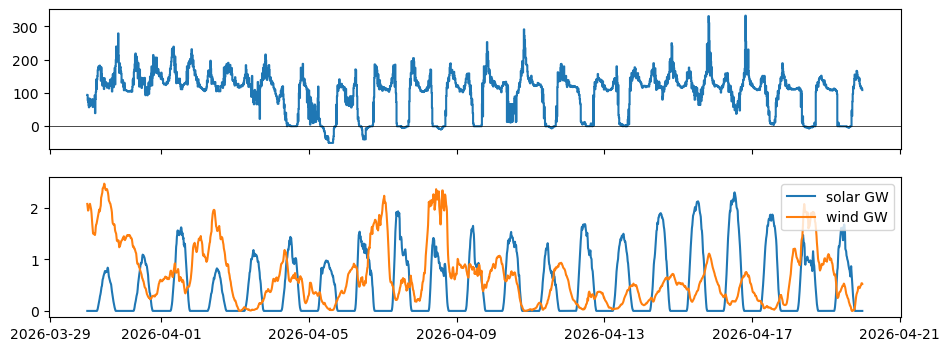

In [9]:
negm = PX.loc[(PX['RO'] < 0) & (PX.index.year == Y), 'dur']
negm = negm.groupby(negm.index.to_period('M')).sum()
CM = negm.idxmax(); print('month:', CM, '| negative hours %.2f' % negm.max())
mk = pd.Series(PX.index.to_period('M') == CM, index=PX.index)
cp, base, _ = capture('RO', 'solar', mk)
print('solar capture rate %.1f%% (%.1f vs %.1f EUR/MWh)' % (cp / base * 100, cp, base))
d2 = pf2[[pd.Period(t, 'M') == CM for t in pf2.index]]
print('2-hour battery: %.0f EUR/MW per day in the month' % d2.mean())
wk0 = (d2.index[0] - pd.Timedelta(days=d2.index[0].dayofweek))
w = PX[(PX.index.tz_localize(None) >= wk0) & (PX.index.tz_localize(None) < wk0 + pd.Timedelta(days=21))]
fig, ax = plt.subplots(2, 1, figsize=(11, 4), sharex=True)
ax[0].step(w.index.tz_localize(None), w['RO'], where='post'); ax[0].axhline(0, color='k', lw=0.5)
ax[1].plot(w.index.tz_localize(None), ro.loc[w.index, 'solar'] / 1000, label='solar GW'); ax[1].plot(w.index.tz_localize(None), ro.loc[w.index, 'wind_onshore'] / 1000, label='wind GW')
ax[1].legend(); plt.show()